## Executive Summary:

- All of the Test 1 matrices behave as expected. I find both the signed sparsity plots and the sign comparison plots informative and nice to look at. You almost certainly only need a subset of the plots present to demonstrate the main point in your slides.
- Test 2A matrices behave as expected, causing high error in non-O(n^3)+FP implementations except for the O(n^3) + emulation + scaling implementations.
- Test 2B matrices do not behave as expected for the emulation code: they cause high error in ALL non-O(n^3)+FP and they are NOT gamed by Emulation + FP64 Diagonal computation.
    - I believe this is to do with a shortcoming in the source code for the emulation. Even the vanilla OZIMMU code (i.e., without my scaling and FP64 diagonal computations wrapping it) zeroes out entries of enormous magnitude. I am also observing this behavior with the vanilla OZIMMU on Test2A matrices but the scaling fixes it there. The circular shifting which defeats the OZIMMU scaling is causing the largest errors in the off diagonals so adding FP64 diagonal computations does little to help. I have to think more on this.
- Test 2C matrices behave as expected, causing high error in ALL non-O(n^3)+FP

In [2]:
import h5py
import pandas as pd
import plotly.express as px
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

DOUBLE_MACHINE_EPS = 2**-52
MATPLOTLIB_SHAPES = ['.','o', '^', 's', 'P', 'X', 'D']
MATPLOTLIB_COLOR_IDX = 0
MATPLOTLIB_SHAPE_IDX = 0

def get_matrix(query, metadata_df, matrices_dict, exact_str_match=False):
    temp_df = metadata_df
    for field, value in query.items():
        if isinstance(value, str):
            if exact_str_match:
                temp_df = temp_df[temp_df[field] == value]
            else:
                temp_df = temp_df[temp_df[field].str.contains(value)]
        else:
            temp_df = temp_df[temp_df[field] == value]
    if len(temp_df) > 1:
        print("Found multiple matches!")
        print(temp_df)
        return None
    elif len(temp_df) == 0:
        print("Found no matches!")
        return None
    else:
        return matrices_dict[f'{temp_df["matrix_id"].iloc[0]}'][:]

# for a given matrix type and a given implementation, plot boxplots of the componentwise nomalized error ratio for each dimension
def plot_all_componentwise_fn_factors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]
    filtered_normalizing_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == "ABS_A_AND_B_" + ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise forward error constants
    # note the potential divide-by-zero issue here
    dims = []
    all_forward_error_constants = []
    for mat_id, ref_mat_id, normalizing_mat_id in zip(filtered_ids, filtered_ref_ids, filtered_normalizing_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        normalizing_mat = matrices_dict[f"{normalizing_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        normalizing_vals = normalizing_mat.flatten()
        all_forward_error_constants.append(abs((vals - ref_vals) / (DOUBLE_MACHINE_EPS * normalizing_vals)))
    
    # plot
    ax.boxplot(all_forward_error_constants, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}", y=1.05)
    ax.tick_params("x", rotation=45)

# for a given matrix type and a given implementation, plot the max of the componentwise nomalized error ratio for each dimension
def plot_max_componentwise_fn_factors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    global MATPLOTLIB_COLOR_IDX
    global MATPLOTLIB_SHAPE_IDX
    global MATPLOTLIB_SHAPES
    
    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]
    filtered_normalizing_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == "ABS_A_AND_B_" + ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate max componentwise forward error constants
    # note the potential divide-by-zero issue here
    dims = []
    max_forward_error_constants = []
    for mat_id, ref_mat_id, normalizing_mat_id in zip(filtered_ids, filtered_ref_ids, filtered_normalizing_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        normalizing_mat = matrices_dict[f"{normalizing_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        normalizing_vals = normalizing_mat.flatten()

        max_forward_error_constants.append(max(abs((vals - ref_vals) / (DOUBLE_MACHINE_EPS * normalizing_vals))))
    
    # plot
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.plot(
        dims,
        max_forward_error_constants,
        c = list(mpl.colors.TABLEAU_COLORS.values())[MATPLOTLIB_COLOR_IDX],
        marker = MATPLOTLIB_SHAPES[MATPLOTLIB_SHAPE_IDX],
        markersize = 16,
        label=f"{impl.split('-')[0]}"
    )
    ax.set_title(f"{impl.split('-')[0]}", y=1.05)
    MATPLOTLIB_COLOR_IDX = (MATPLOTLIB_COLOR_IDX + 1)%len(mpl.colors.TABLEAU_COLORS)
    MATPLOTLIB_SHAPE_IDX = (MATPLOTLIB_SHAPE_IDX + 1)%len(MATPLOTLIB_SHAPES)
    
# for a given matrix type and a given implementation, plot boxplots of the componentwise relative errors for each dimension
def plot_all_componentwise_unsigned_relative_errors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise_unsigned_relative_errors
    # note the potential divide-by-zero issue here
    dims = []
    unsigned_relative_errors = []
    for mat_id, ref_mat_id in zip(filtered_ids, filtered_ref_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        unsigned_relative_errors.append(abs((vals - ref_vals) / ref_vals))
    
    # plot
    ax.boxplot(unsigned_relative_errors, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}")
    #ax.set_yscale("log", base=2)
    ax.tick_params("x", rotation=45)

# for a given matrix type and a given implementation, plot boxplots of the componentwise absolute errors for each dimension
def plot_all_componentwise_unsigned_absolute_errors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_ref_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise_unsigned_absolute_errors
    dims = []
    unsigned_absolute_errors = []
    for mat_id, ref_mat_id in zip(filtered_ids, filtered_ref_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        ref_mat = matrices_dict[f"{ref_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        ref_vals = ref_mat.flatten()
        unsigned_absolute_errors.append(abs(vals - ref_vals))
    
    # plot
    ax.boxplot(unsigned_absolute_errors, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}")
    #ax.set_yscale("log", base=2)
    ax.tick_params("x", rotation=45)

def plot_matrix_sparsity(input_type, impl, problem_size, metadata_df, matrices_dict, ax):

    # query metadata df for id of desired matrix
    matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    
    A = matrices_dict[f"{matrix_id.iloc[0]}"][:].astype(np.float64)

    ax.set_title(f"{impl.split('-')[0]}")
    
    bounds = [-0.5, 0.5, 1.5]
    
    cmap = mpl.colors.ListedColormap(["none", "red"])
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    ax.spy(A<0, cmap=cmap, norm=norm)

    cmap = mpl.colors.ListedColormap(["none", "green"])
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    ax.spy(A>0, cmap=cmap, norm=norm)
    
    cmap = mpl.colors.ListedColormap(["none", "white"])
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    ax.spy(A==0, cmap=cmap, norm=norm)

    ax.text(x=problem_size/2, y=problem_size+0.05*(problem_size), s=f"# zeros: {(A==0).sum()}", horizontalalignment="center")
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])

def plot_matrix_sparsity_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, ax):

    # query metadata df for id of desired matrices
    matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    ref_matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    
    A = matrices_dict[f"{matrix_id.iloc[0]}"][:].astype(np.float64)
    A_ref = matrices_dict[f"{ref_matrix_id.iloc[0]}"][:].astype(np.float64)

    ax.set_title(f"{impl.split('-')[0]}")
    
    bounds = [-0.5, 0.5, 1.5]
    
    cmap = mpl.colors.ListedColormap(["white", "black"])
    norm = mpl.colors.BoundaryNorm(bounds, cmap.N)
    ax.spy(np.sign(A_ref) != np.sign(A), cmap=cmap, norm=norm)

    ax.text(x=problem_size/2, y=problem_size+0.05*(problem_size), s=f"# zeros: {(A==0).sum()}", horizontalalignment="center")
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])

def plot_matrix_relative_error_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, ax):

    # query metadata df for id of desired matrices
    matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    ref_matrix_id = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == ref_impl) & (metadata_df["m"] == problem_size)]["matrix_id"]
    
    A = matrices_dict[f"{matrix_id.iloc[0]}"][:].astype(np.float64)
    A_ref = matrices_dict[f"{ref_matrix_id.iloc[0]}"][:].astype(np.float64)

    ax.set_title(f"{impl.split('-')[0]}")

    im = ax.imshow(np.abs(A_ref - A)/(A_ref))
    ax.figure.colorbar(im, ax=ax, shrink=0.5)
    
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])

In [3]:
#h5_file.close()
h5_file = h5py.File("grading_dgemm.h5", "r")

matrices_dict = h5_file["matrices"]

metadata_df = pd.DataFrame(h5_file["metadata"][:])
metadata_df["matrix_name"] = metadata_df["matrix_name"].str.decode("utf-8")
metadata_df["input_type"] = metadata_df["input_type"].str.decode("utf-8")
metadata_df["matrix_name"].unique()

array(['A', 'B', 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_SCALING_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_SCALING_AND_FP64_DIAGONAL_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'ABS_A_AND_B_NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3'],
      dtype=object)

In [5]:
ref_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3"

impls = [
       #'A',
       #'B',
       'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_SCALING_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'OZIMMU_SCALING_AND_FP64_DIAGONAL_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_SCALING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       'STRASSEN_SCALING_AND_ZEROING_BASECASE_2-a65ae05-GNU_13.2-O0-x86_64_zen3',
       #'ABS_A_AND_B_NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3'
]

n_rows = 2
n_cols = 6

# Test 1

## Test-1A
> The simplest way to identify Strassen-like routines is to choose $A = randn(n,n)$
and $B=randn(n,n)$, and set a few randomly chosen rows of $A$ and columns of $B$ to zero. 
Any $O(n^3)$ algorithm (with any arithmetic) will compute $A\cdot B$ with the same 
rows and columns of $C$ equal to zero, but Strassen will not with high
probability (w.h.p), because of rounding errors during cancellation. 
\jwd{I verified this on some small numerical examples.} 
>
> However, this very simple test can be gamed using the idea at the end of
Section~\ref{sec:grading}. If an implementation of Strassen tries to scale 
the rows of $A$ and columns of $B$ to have unit norms to try to earn a "B", 
it will detect zero rows and columns, which can be zeroed out in the product $C$, 
at $O(n^2)$ cost, and so Strassen could pass Test\_1a. We try to address this weakness with Test\_1b.

__As expected, adding scaling to Strassen successfully games the Test-1A__

In [5]:
problem_size = 64 

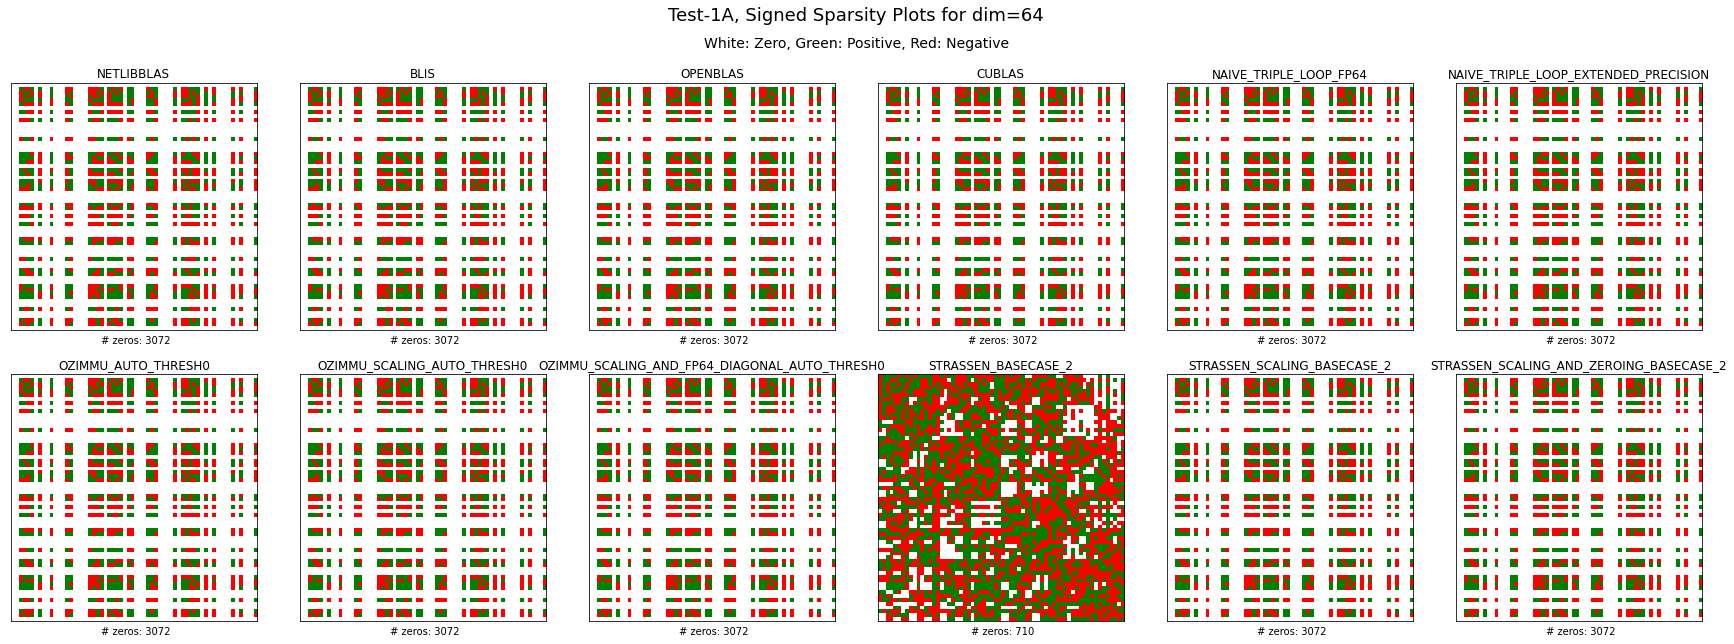

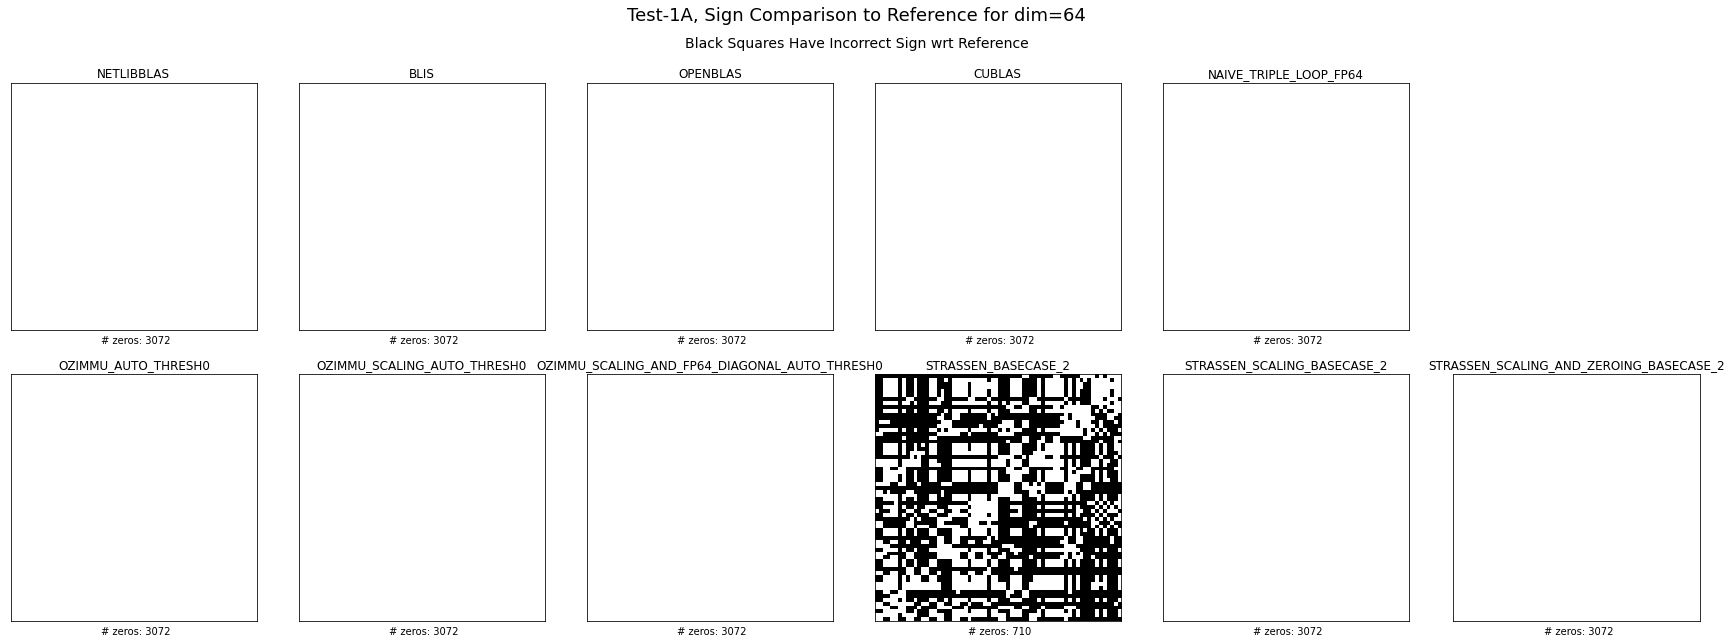

In [10]:
input_type = "test1a"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-1A, Signed Sparsity Plots for dim={problem_size}", size=18, y=1.1)
fig.text(x=0.5, y=1.03, s="White: Zero, Green: Positive, Red: Negative", size=14, horizontalalignment="center")
for subplot_idx, impl in enumerate(impls):
    plot_matrix_sparsity(input_type, impl, problem_size, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-1A, Sign Comparison to Reference for dim={problem_size}", size=18, y=1.1)
fig.text(x=0.5, y=1.03, s="Black Squares Have Incorrect Sign wrt Reference", size=14, horizontalalignment="center")
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_matrix_sparsity_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

## Test 1-B
> Start with $A = randn(n,n)$ and $B = randn(n,n)$. Pick a random subset of $1<k<n$ rows of $A$, 
labeled $(i_1, \ldots, i_k)$, and $k$ random columns of $B$, labeled $(j_1, \ldots, j_k)$. For each $m\in [1:k]$, pick a 
random proper subset $S_m$ of $[1:n]$, and zero out entries $A(i_m,r)$ for all $r\in S_m$,
and zero out entries $B(s, j_m)$ for all $s$ not in $S_m$. This means that the dot
product $A(i_m, :)\cdot B(:, j_m) = (A\cdot B)(i_m, j_m)$ is exactly zero. If each $(A\cdot B)(i_m, j_m)$
is computed as a conventional dot product, it will be a sum of zeros and so exactly zero,
in any precision. But with any Strassen like algorithm, getting zero will require
exact cancellation, which is unlikely. And getting 
exactly $k$ zeros is even more unlikely.
Computing any nonzero value violates the requirement for an "A".
>
>Obviously other sparsity patterns for $A$ and $B$ might work too, but using “minimal”
sparsity as in Test\_1b would seem to maximize the chance of recognizing a Strassen-like
algorithm. \jwd{I verified this on some small numerical examples.} 
Since performant implementations of Strassen-like algorithms will not recurse down to 
$n=1$, but call an $O(n^3)$ algorithm instead on small enough matrices, 
Test\_1b can also be used
to “reverse engineer” the size $n_0$ of matrices at or below which an $O(n^3)$
algorithm is used, by finding the largest matrix that still passes Test\_1b. 
% We use this fact below?

>A failure to compute the expected $k$ zero entries is a clear signal that a
Strassen-like algorithm is being used. In other words, there are no false positive
signals for Strassen.
However, there is another way for a Strassen-like algorithm to ``game'' Test\_1b, 
by setting computed entries of $C$ less than an error bound to zero\footnotemark[1].
Since our test code will be public, a vendor could read our test code and 
precisely decide what this threshold would be. By first scaling the rows of $A$ and 
columns of $B$ to have unit norms (as described in the last paragraph of
Section~\ref{sec:grading}), and setting small values of 
$\hat{C} = (D_1 \cdot A) \cdot (B \cdot D_2)$ to zero this would make the behavior
hard to distinguish from an $O(n^3)$ algorithm using 
emulation, eg.
\cite{Uchino_Ozaki_Imamura_2024}, which earns a "B".

__As expected:__
- __Test 1-B defeats Strassen + scaling alone__
- __Strassen + scaling + zeroing successfully games Test 1-B__

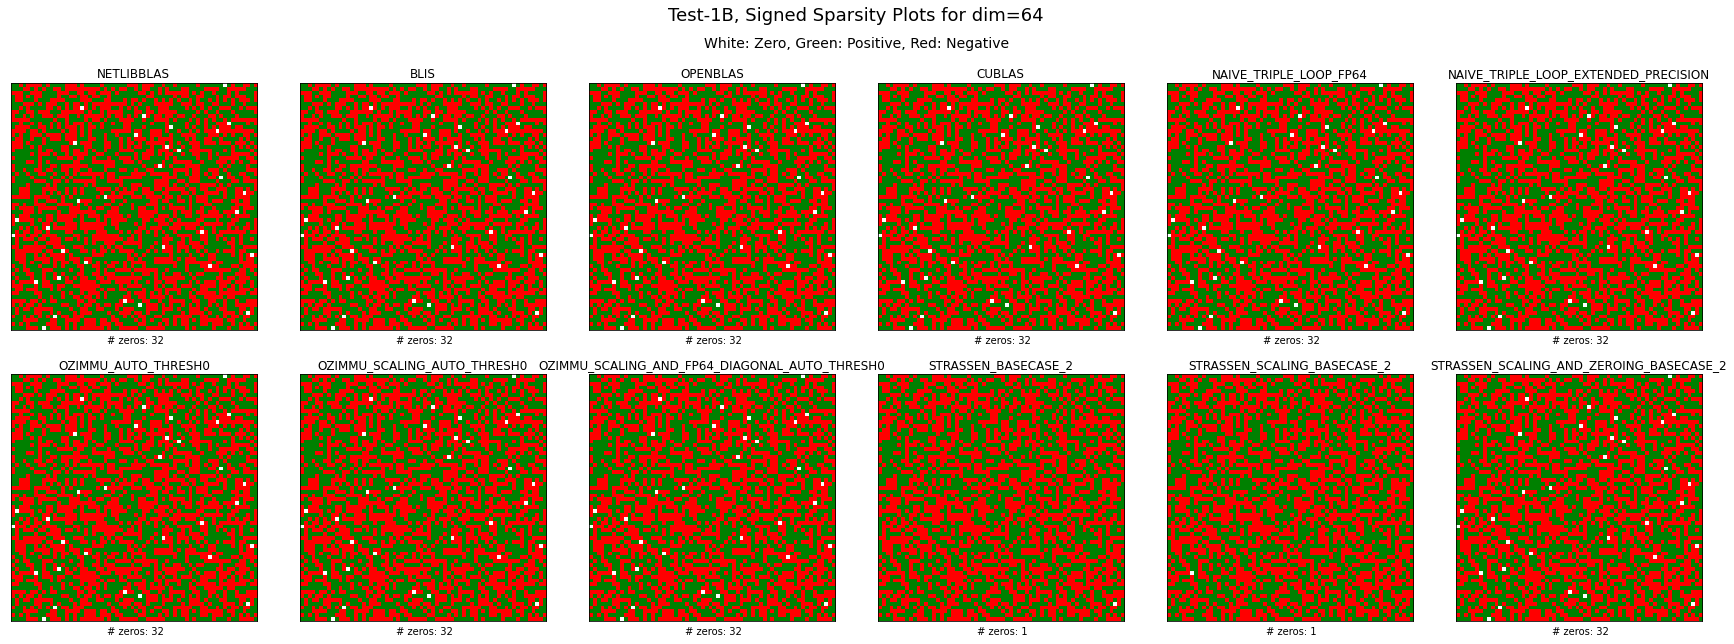

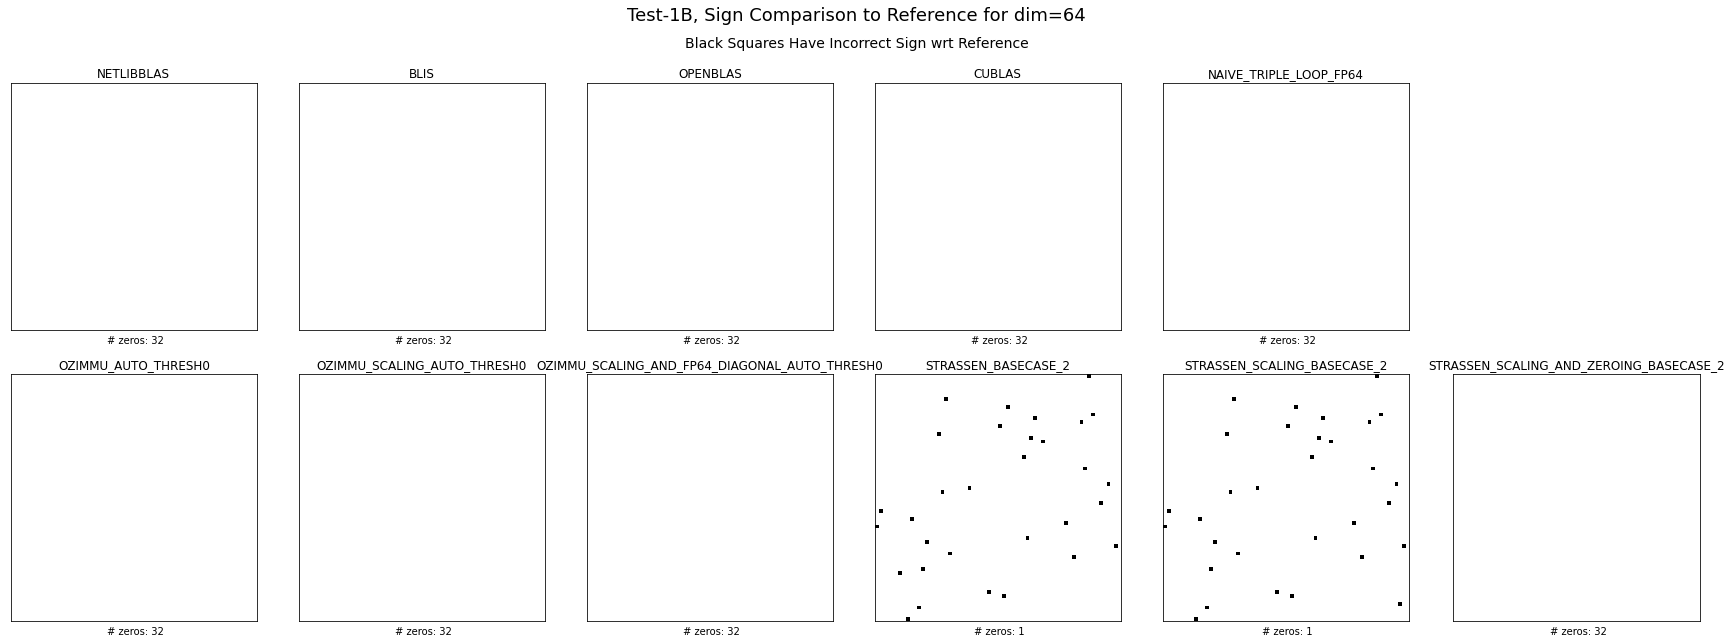

In [11]:
input_type = "test1b"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-1B, Signed Sparsity Plots for dim={problem_size}", size=18, y=1.1)
fig.text(x=0.5, y=1.03, s="White: Zero, Green: Positive, Red: Negative", size=14, horizontalalignment="center")
for subplot_idx, impl in enumerate(impls):
    plot_matrix_sparsity(input_type, impl, problem_size, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-1B, Sign Comparison to Reference for dim={problem_size}", size=18, y=1.1)
fig.text(x=0.5, y=1.03, s="Black Squares Have Incorrect Sign wrt Reference", size=14, horizontalalignment="center")
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_matrix_sparsity_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

## Test 1-C
> We strengthen Test\_1b so that only an $O(n^3)$ algorithm using
conventional floating point can pass it. We take the test matrices $A$ and $B$
proposed for Test\_1b, and in some subset of the $k$ pairs of
rows $A(i_m,:)$ and columns $B(:,j_m)$, we choose a 
random $k_m$ and
% common zero entry $A(i_m,k_m)=B(k_m,j_m)=0$, and 
set $A(i_m,k_m)=B(k_m,j_m)=x$, so
that the correct value of $C(i_m,j_m)=x^2$. 
If we choose the nonzero entries in row $i_m$ of $A$
and column $j_m$ of $B$ that are multiplied by zeros
to be close to $\sqrt{OV}$, $x$ to be close to
$\sqrt{UN}$, and the other entries of $A$ and $B$
to be $O(1)$, then scaling $D_1 \cdot A$ 
(resp. $B \cdot D_2$) to have unit row (resp. column)
norms will make the $x^2$ values underflow to zero, causing an incorrect value $C(i_m,j_m)=0$.
Scaling by $D_3$ will not change the matrices (much)
since all the column norms of $A$ and row norms of $B$
are close to $\sqrt{OV}$.
A Strassen-like algorithm will not compute $x^2$
accurately w.h.p., whether or not it sets tiny entries
of $C$ to zero.
And the use of emulation will set the entries near
$\sqrt{UN}$ to zero, so that an $O(n^3)$ algorithm using
emulation will also compute 0 instead of $x^2$.
In other words, Test\_1c should reliably distinguish
an $O(n^3)$ algorithm using classic floating point,
which deserves an ''A'' grade, from the alternatives.

__As expected:__
- __Test 1-C defeats Strassen + scaling + zeroing__
- __Test 1-C defeats emulation schemes as well__

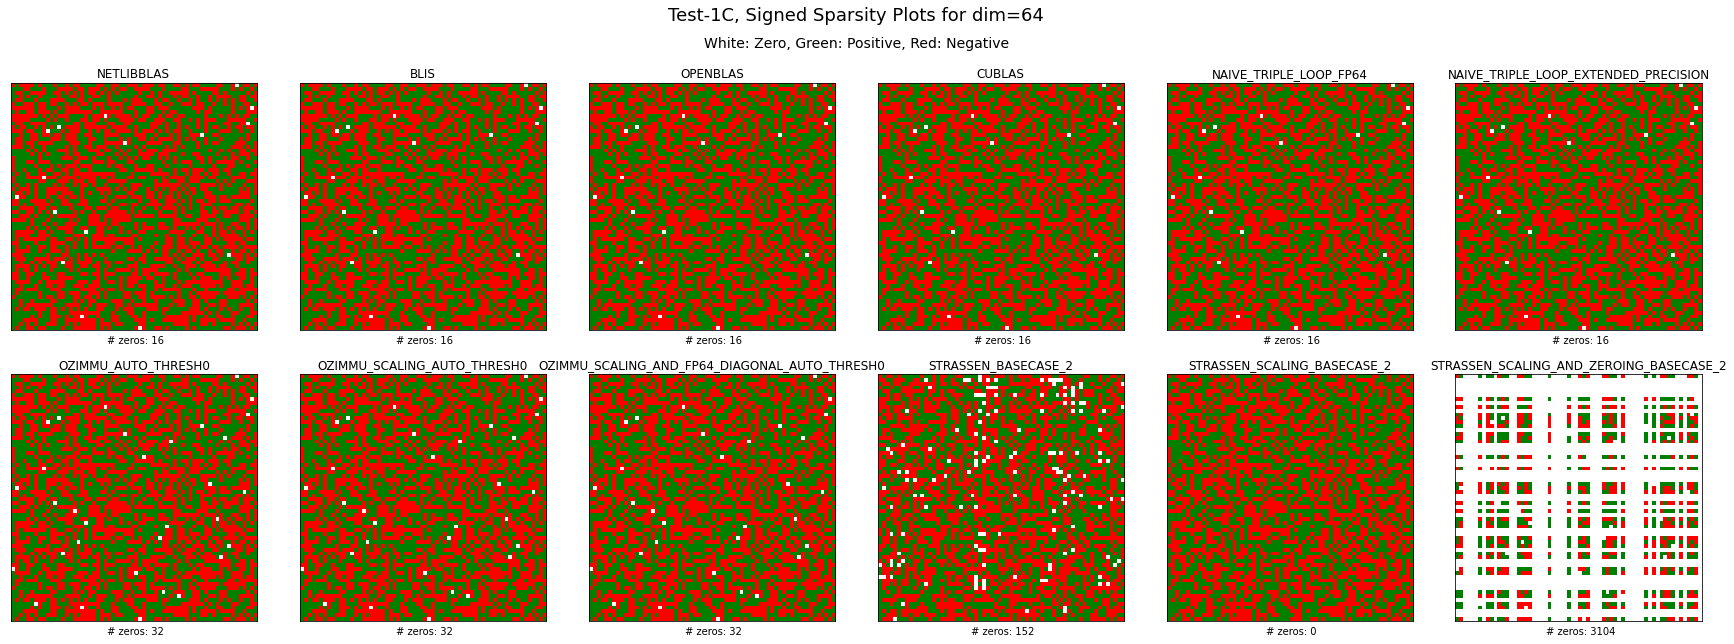

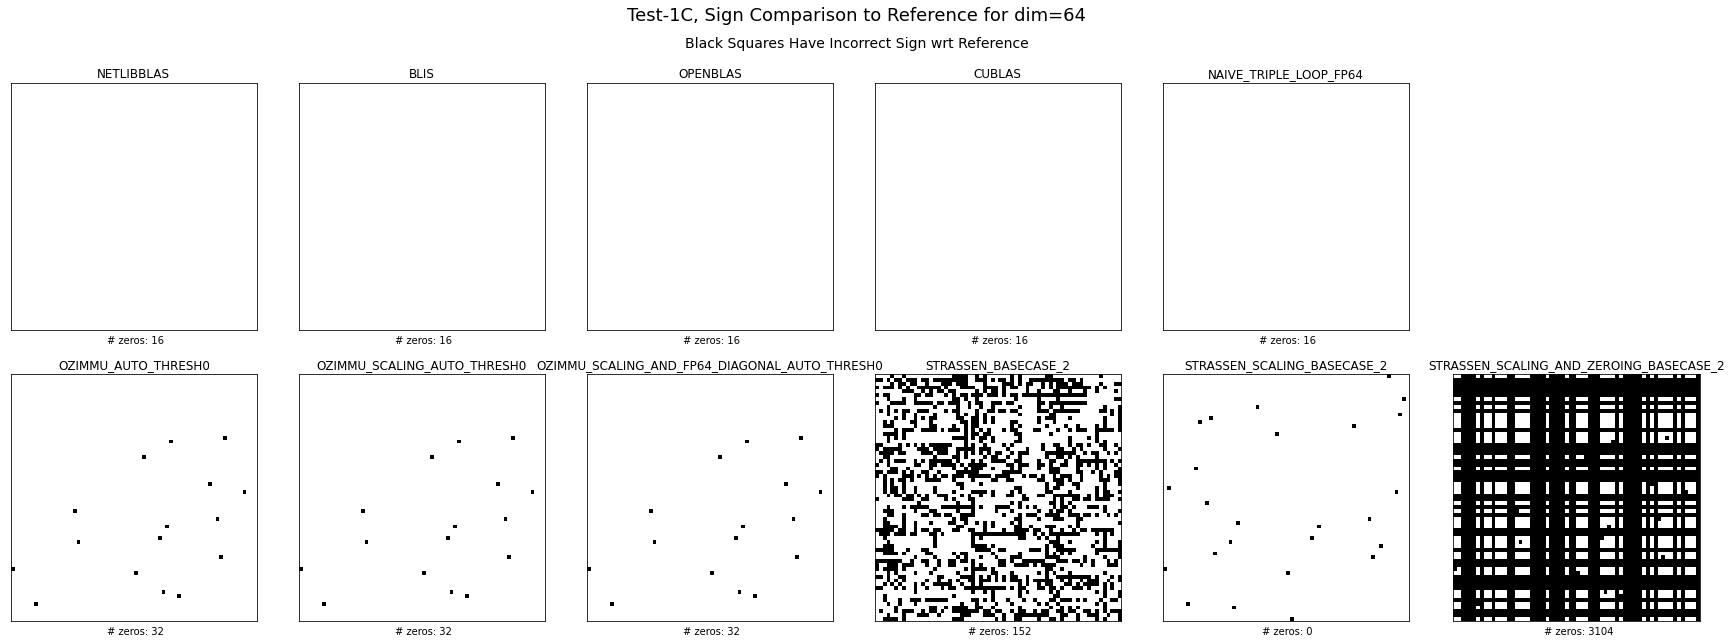

In [12]:
input_type = "test1c"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-1C, Signed Sparsity Plots for dim={problem_size}", size=18, y=1.1)
fig.text(x=0.5, y=1.03, s="White: Zero, Green: Positive, Red: Negative", size=14, horizontalalignment="center")
for subplot_idx, impl in enumerate(impls):
    plot_matrix_sparsity(input_type, impl, problem_size, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-1C, Sign Comparison to Reference for dim={problem_size}", size=18, y=1.1)
fig.text(x=0.5, y=1.03, s="Black Squares Have Incorrect Sign wrt Reference", size=14, horizontalalignment="center")
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_matrix_sparsity_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

# Test 2

## Test-2A
> Let $x = rand(1,n) + 1$ be a random vector with entries in the range [1,2].
Let $D$ be a diagonal matrix with entries equal to powers of two, ranging
from close to overflow to close to underflow, with roughly evenly spaced
exponents. Let $y = x\cdot D$ and $z^T = D^{-1}\cdot x^T$, so that $y\cdot z^T = x\cdot x^T = O(n)$ would be 
computed to high relative accuracy using standard floating point, but an $O(n^3)$ algorithm with emulation
would result in a high relative error unless the entire exponent
range is represented. Now let each row of A equal $y$ and each column of
B equal $z^T$, and test that each entry is accurate, by comparing to the
floating point result
> 
> Test\_2a is easily gamable, for $O(n^2)$ extra cost, by replacing
$A$ by $A\cdot D_3$ and $B$ by $D_3^{-1}\cdot B$, where the diagonal matrix $D_3$ is chosen
so that the i-th column of A and i-th row of B each has (about) the same norm,
effectively changing each row of $A\cdot D_3$ back to $x$ and each column of $D_3^{-1}\cdot B$ 
back to $x^T$. Note that this diagonal scaling  will
also greatly improve the accuracy 
of Strassen, by reducing $\|A\| \cdot \|B\| = O(OV^2)$ 
to $\|A\cdot D_3\|\cdot \|D_3^{-1}\cdot B\| = O(1)$.

__As expected, emulation with scaling effectively beats Test-2A.__

__Test-2A also defeats the tested Strassen implementations.__

__(Note that `STRASSEN_BASECASE_2` is missing because of overflows yielding NaN values in the output)__

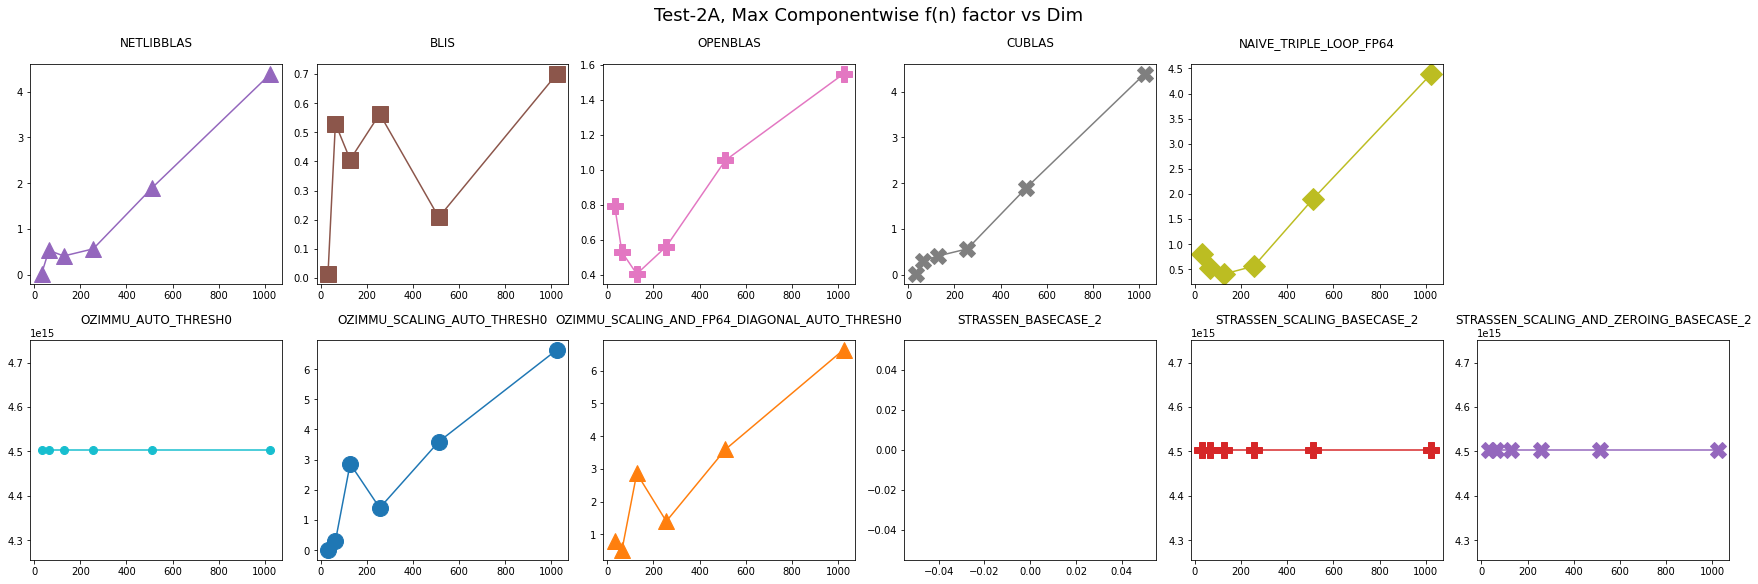

In [61]:
input_type = "test2a"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-2A, Max Componentwise f(n) factor vs Dim", size=18)
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_max_componentwise_fn_factors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

## Test-2B
> We can try to prevent the gaming of Test\_2a as follows: for each $i \in [1:n]$,
circularly shift each row of $A$ right by $i$, and circularly shift each column of $B$
down by $i$. Then each row and column of $A$ and of $B$ has the same norm, so any
diagonal scaling is pointless, and the diagonal entries of $A\cdot B$ should all equal
$x\cdot x^T$ to high relative accuracy in floating point. We should also reduce the range of 
numbers in the diagonal matrix $D$ used to compute $y=x\cdot D$ to go from roughly $\sqrt{UN}$ to
$\sqrt{OV}$, to avoid underflow and overflow.

__Here, it appears that emulation with scaling and an FP64-calculated diagonal fails to game Test-2B as expected.__

__Consider the heatmaps below: it seems as though the underlying OZIMMU implementation is mishandling the wide range of scales in the inputs and zeroing out nonzero entries.__
All of the bright regions in the heatmaps for OZIMMU and STRASSEN+ZEROING are zeros. These zeroed entries in the reference are massive. When decreasing the magnitude of the entries in the diagonal used to scale the input matrices, the zeroing is less aggressive.

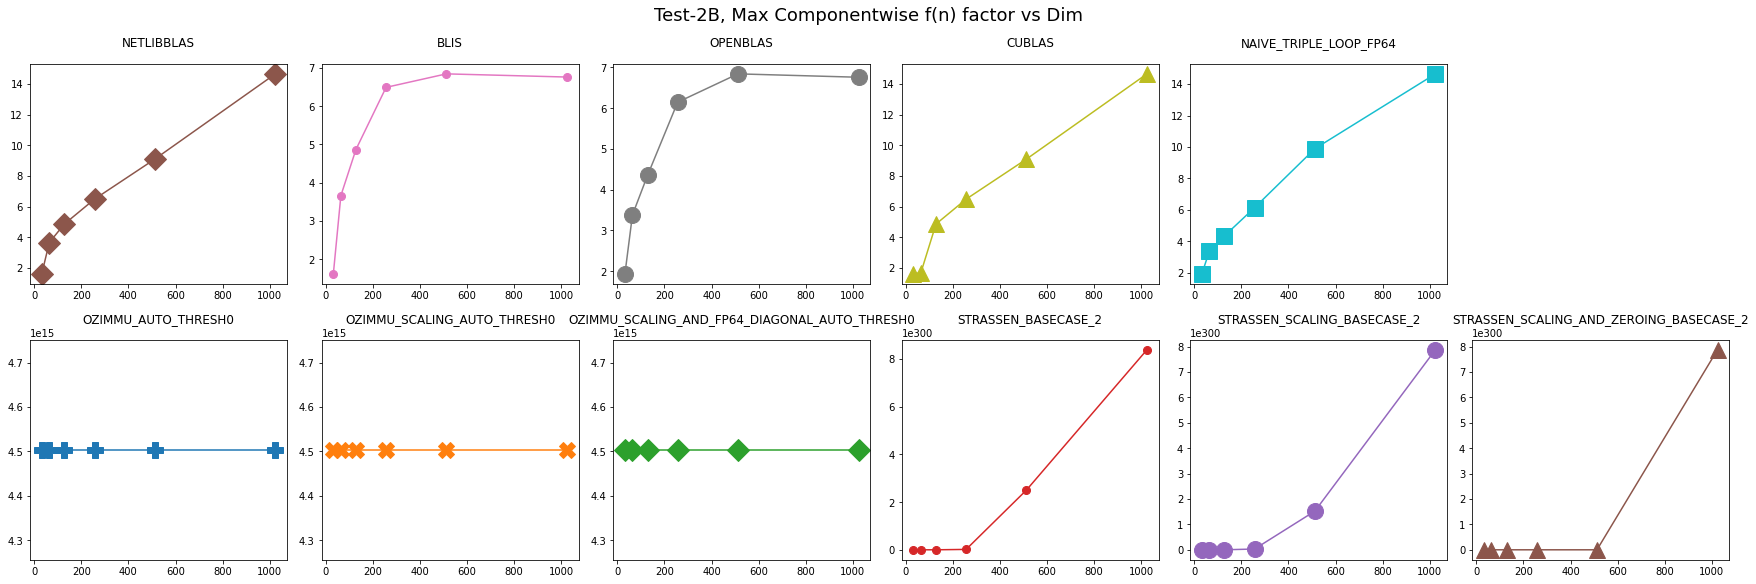

In [62]:
input_type = "test2b"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-2B, Max Componentwise f(n) factor vs Dim", size=18)
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_max_componentwise_fn_factors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

In [7]:
query = {
    "matrix_name" : "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3",
    "m" : 32,
    "input_type" : "test2b"
}
print("Entries on the 5-diagonal in the reference:")
np.diagonal(get_matrix(query, metadata_df, matrices_dict, exact_str_match=True), offset=5)

Entries on the 5-diagonal in the reference:


array([6.59898083e+48, 6.59898083e+48, 6.59898083e+48, 6.59898083e+48,
       6.59898083e+48, 6.59898083e+48, 6.59898083e+48, 6.59898083e+48,
       6.59898083e+48, 6.59898083e+48, 6.59898083e+48, 6.59898083e+48,
       6.59898083e+48, 6.59898083e+48, 6.59898083e+48, 6.59898083e+48,
       6.59898083e+48, 6.59898083e+48, 6.59898083e+48, 6.59898083e+48,
       6.59898083e+48, 6.59898083e+48, 6.59898083e+48, 6.59898083e+48,
       6.59898083e+48, 6.59898083e+48, 6.59898083e+48], dtype=float128)

In [8]:
query = {
    "matrix_name" : "OZIMMU_SCALING_AUTO_THRESH0",
    "m" : 32,
    "input_type" : "test2b"
}
print("Entries on the 5-diagonal in the vanilla OZIMMU:")
np.diagonal(get_matrix(query, metadata_df, matrices_dict), offset=5)

Entries on the 5-diagonal in the vanilla OZIMMU:


array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

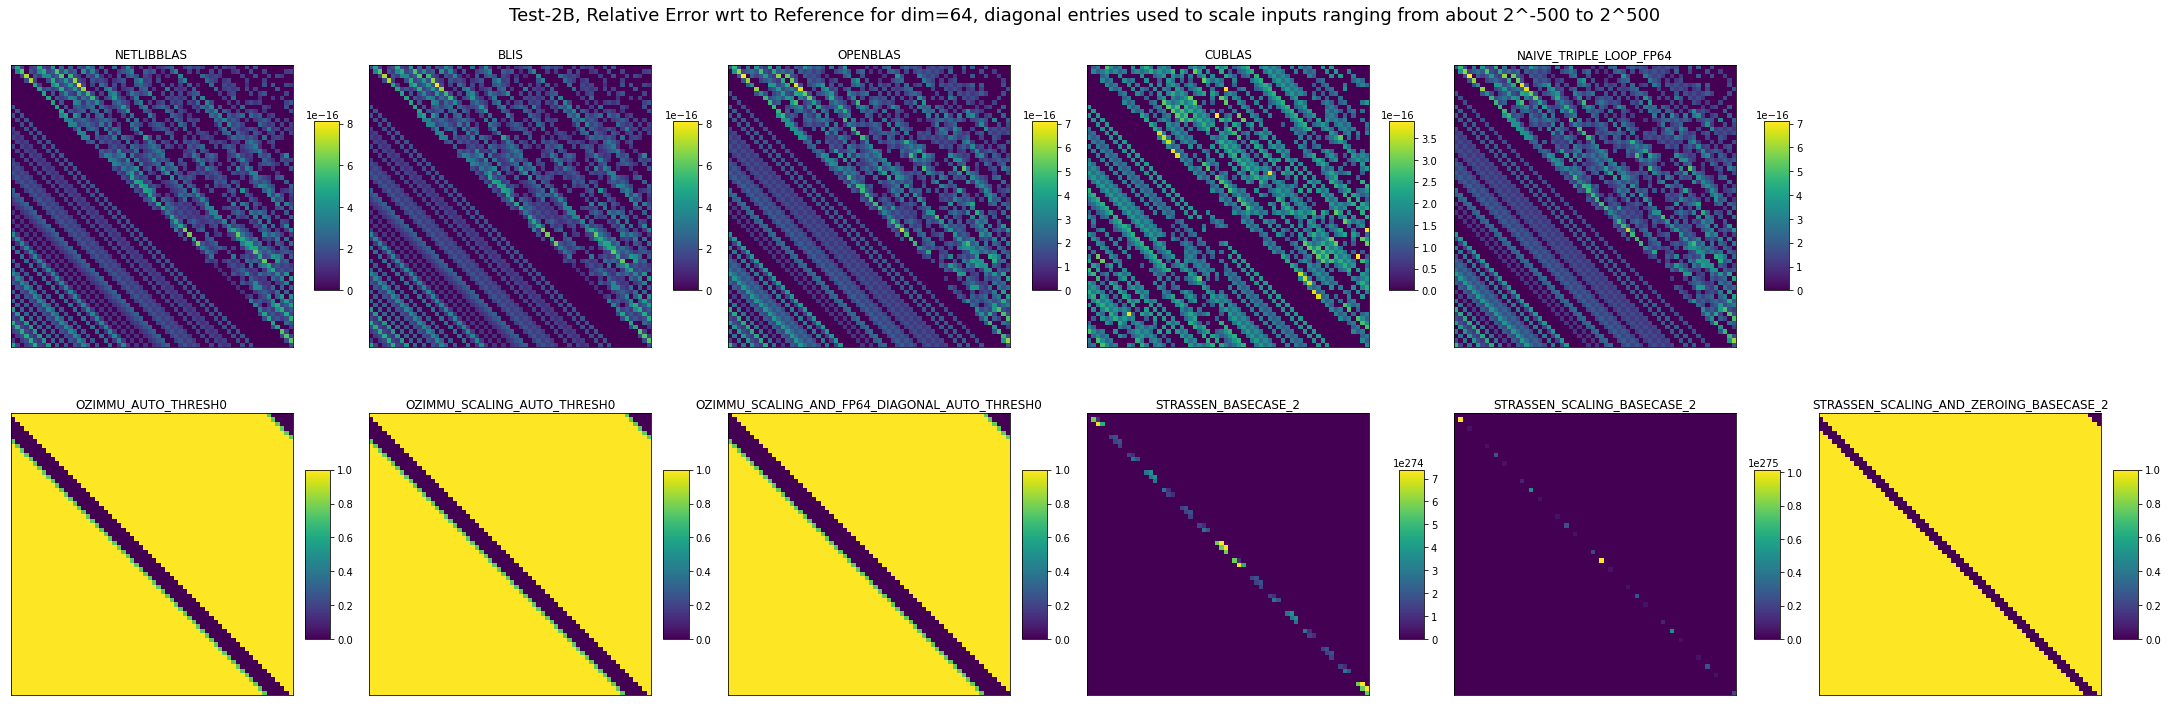

In [6]:
input_type = "test2b"

problem_size = 64

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*5, n_rows*5), constrained_layout=True)
fig.suptitle(f"Test-2B, Relative Error wrt to Reference for dim={problem_size}, diagonal entries used to scale inputs ranging from about 2^-500 to 2^500", size=18)
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_matrix_relative_error_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

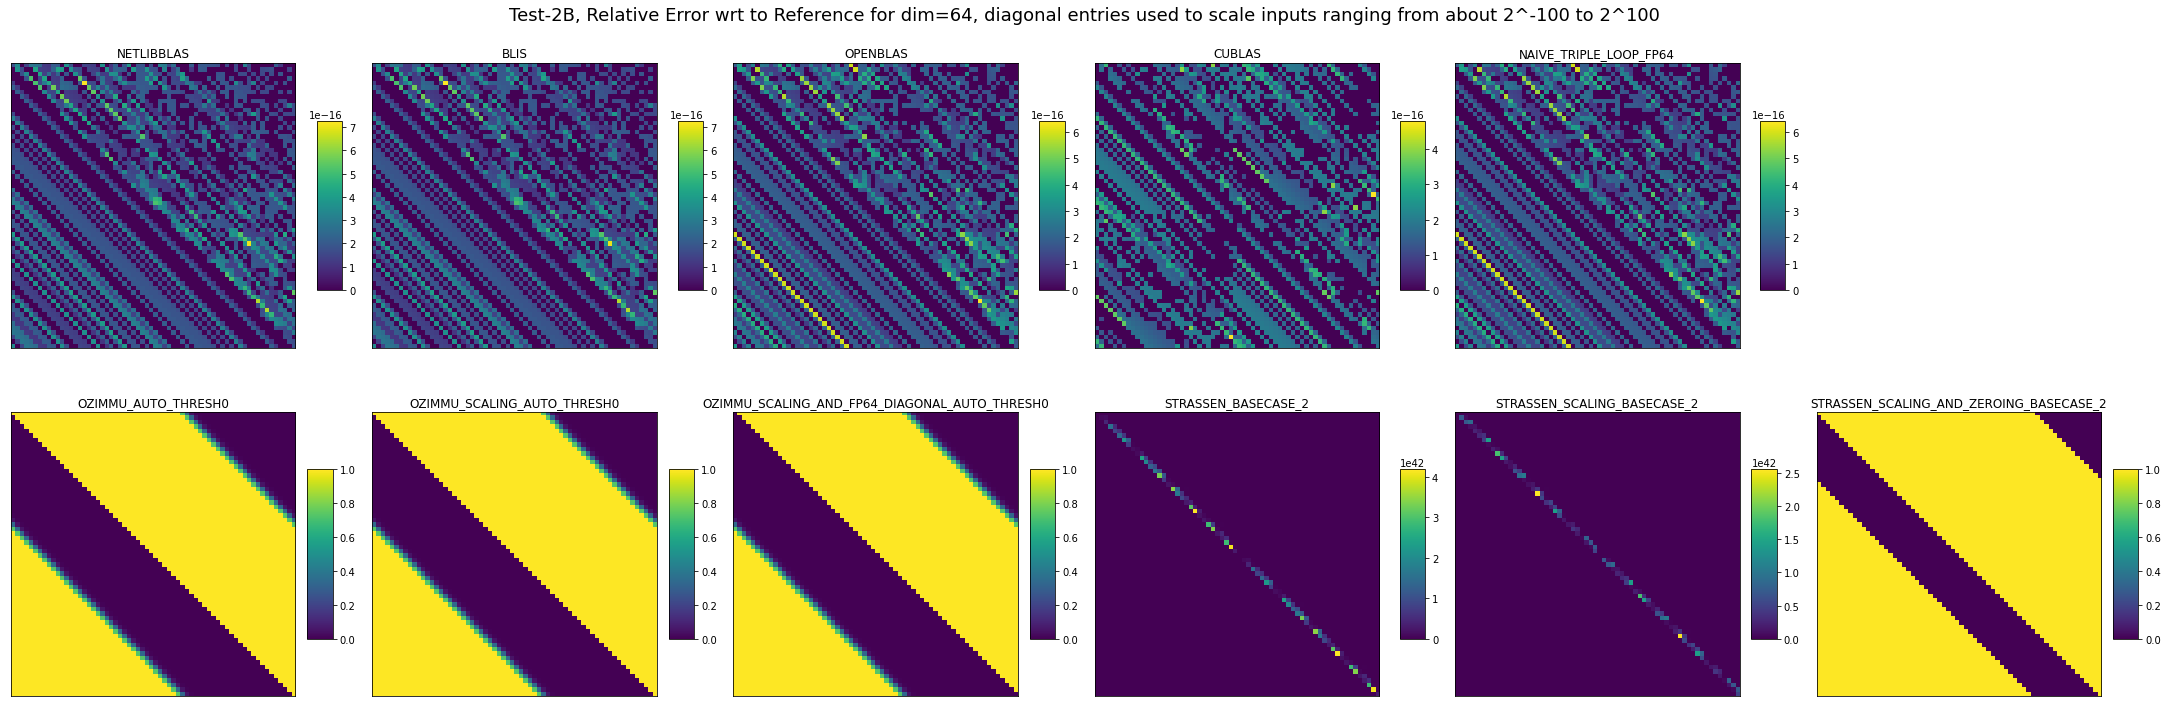

In [68]:
input_type = "test2b"

problem_size = 64

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*5, n_rows*5), constrained_layout=True)
fig.suptitle(f"Test-2B, Relative Error wrt to Reference for dim={problem_size}, diagonal entries used to scale inputs ranging from about 2^-100 to 2^100", size=18)
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_matrix_relative_error_against_reference(input_type, impl, ref_impl, problem_size, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()

## Test 2-C
> Unfortunately, Test\_2b is still gamable,
by using conventional floating point to compute just
the diagonal entries of $A \cdot B$ to high accuracy,
for an extra $O(n^2)$ cost. Instead, we can randomize the
locations of these $n$ accurate entries, so that it is
too expensive to detect their locations and compute them
with extra precision. Simply choose random permutation
matrices $P_1$ and $P_2$, and replace $A$ by $P_1 \cdot A$,
and $B$ by $B \cdot P_2$. The entries of the product
to test for accuracy are the nonzero entries of $P_1 \cdot P_2$.

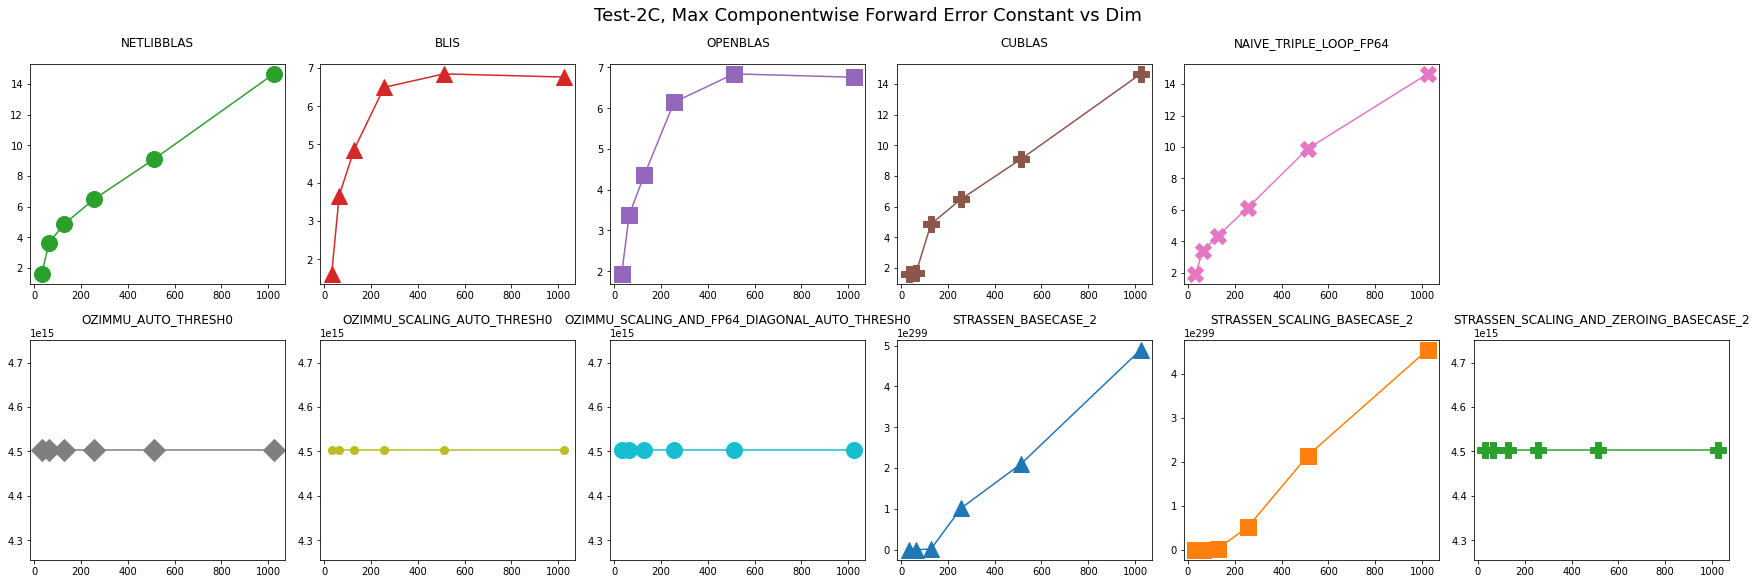

In [17]:
input_type = "test2c"

fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4), constrained_layout=True)
fig.suptitle(f"Test-2C, Max Componentwise Forward Error Constant vs Dim", size=18)
for subplot_idx, impl in enumerate(impls):
    if impl == ref_impl:
        fig.delaxes(axs[subplot_idx//n_cols, subplot_idx%n_cols])
    else:
        plot_max_componentwise_fn_factors_vs_dim(input_type, impl, ref_impl, metadata_df, matrices_dict, axs[subplot_idx//n_cols, subplot_idx%n_cols])
fig.show()